# House Prices : exploration #
Goal : understand the data before building a model

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

print(train.shape, test.shape)
train.head()


(1460, 81) (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
train.info()
train.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


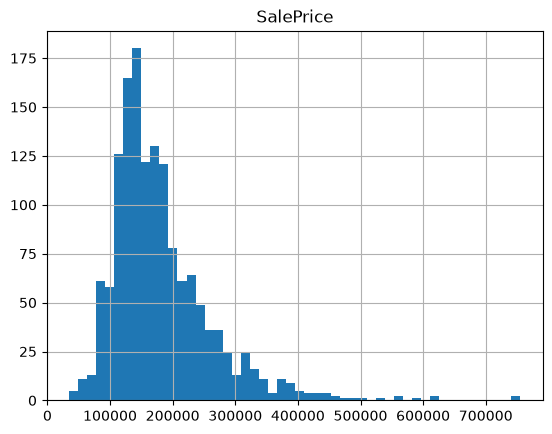

skew: 1.8828757597682129


In [6]:
# histogram
train["SalePrice"].hist(bins=50)
plt.title("SalePrice")
plt.show()
print("skew:",train["SalePrice"].skew())

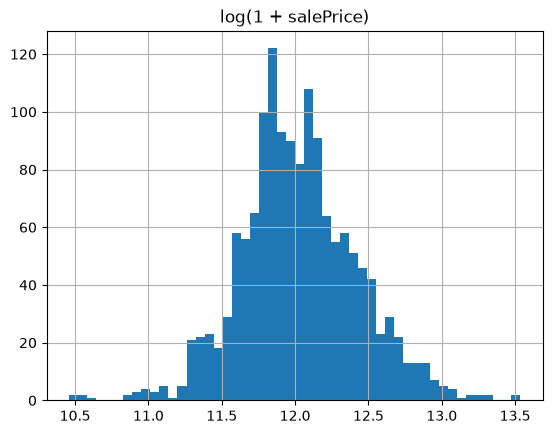

skew: 1.0587883236479845


In [7]:
np.log1p(train["SalePrice"]).hist(bins=50)
plt.title("log(1 + salePrice)")
plt.show()
print("skew:", np.log1p(train["SalePrice"].skew()))

## SalePrice VS log(1 + SalePrice) : ##
skewness measures how assymetric a distribution is (0=symmetric, positive = long right tail)
SalePrice has a skew of around 1.88 ; After log1p, it drops to 1.05
The competition scores errors on the log scale, so we will train on log1p(SalePrice) and convert back with expm1 at the end

## Missing values ## 
Before preprocessing, we'll take a look at the missing values

In [9]:
train.isnull().sum().sort_values(ascending=False).head(20)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
Id                 0
dtype: int64

Specific look at the column with the most "NA" : 
*PoolQC :* the missing values correspond to the houses that do not have a pool, which is an information we want to keep when building our model even though there are a lot of "NA" in this column
*MiscFeature :* the missing values correspond to the houses that do not have additional features such as Tennis court or second garage ; we also want to keep this information

In [14]:
## calculating Mutual Information to determine if we can drop Alley
from sklearn.feature_selection import mutual_info_regression

alley = train["Alley"].fillna("None").astype("category").cat.codes # giving an integer label to each string category
mi_alley = mutual_info_regression(alley.to_frame(), np.log1p(train["SalePrice"]),discrete_features=True, random_state=0)
print("mi for Alley : ", mi_alley)

mi_overallqual = mutual_info_regression(train["OverallQual"].to_frame(), np.log1p(train["SalePrice"]), discrete_features = True, random_state=0)
print("mi for OverallQual : ", mi_overallqual)

neighb = train["Neighborhood"].astype("category").cat.codes
mi_neighb = mutual_info_regression(neighb.to_frame(), np.log1p(train["SalePrice"]), discrete_features=True, random_state=0)
print("mi for Neighborhood : ", mi_neighb)


mi for Alley :  [0.02304458]
mi for OverallQual :  [0.57013493]
mi for Neighborhood :  [0.5264266]


mi for Alley is close to 0.02, which is really small comparing to OverallQual(0.57) or Neighborhood(0.52)
maybe we can drop the column Alley later on ?

## Other columns to look at ##

MSSubClass
20     536
30      69
40       4
45      12
50     144
60     299
70      60
75      16
80      58
85      20
90      52
120     87
160     63
180     10
190     30
Name: count, dtype: int64


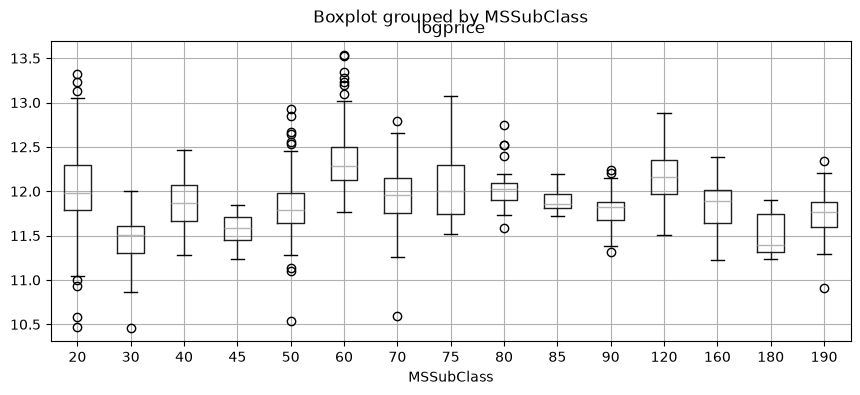

In [ ]:
print(train["MSSubClass"].value_counts().sort_index())

train.assign(logprice=np.log1p(train["SalePrice"])).boxplot(
    column="logprice", by="MSSubClass", figsize=(10, 4))   

#train.assign(logprice=...) returns a temporary copy of train with extra column logprice
#.boxplot(...) one box summarizing the logprice of the houses for evry group of MSSubClass
plt.show()

What we can see : the box prices do not follow the order of the MSSubClass number associated with the categories
--> MSSubClass should be treated as a categorical feature rather than a number

OverallQual
1       2
2       3
3      20
4     116
5     397
6     374
7     319
8     168
9      43
10     18
Name: count, dtype: int64


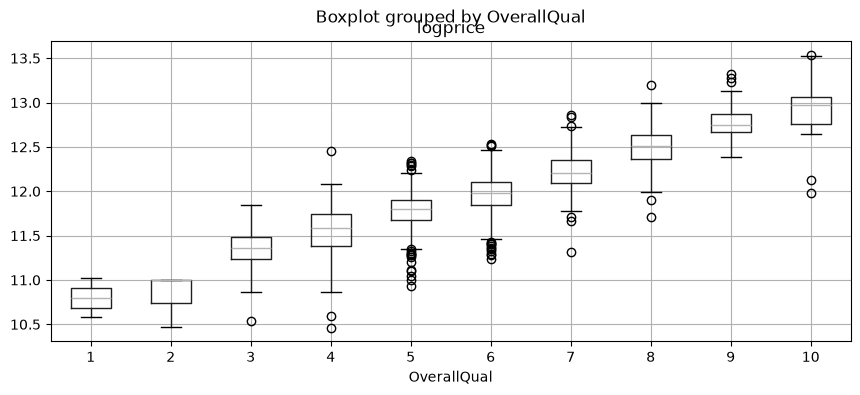

In [16]:
print(train["OverallQual"].value_counts().sort_index())

train.assign(logprice=np.log1p(train["SalePrice"])).boxplot(column="logprice", by="OverallQual", figsize=(10,4))
plt.show()

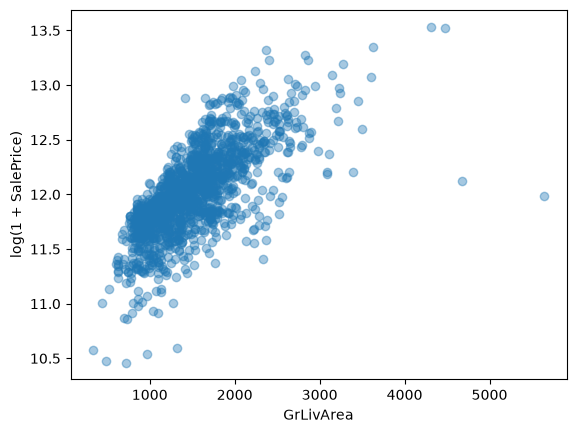

Correlation between OverallQual and logprice :  0.8171846144867665 ; Correlation between GrLivArea and logprice :  0.7009269871427151
Correlation between log(GrLivArea) and logprice :  0.7302537651626401


,GrLivArea,SalePrice
1169,3627,625000
691,4316,755000
1182,4476,745000
523,4676,184750
1298,5642,160000


In [26]:
plt.scatter(train["GrLivArea"], np.log1p(train["SalePrice"]), alpha=0.4)
plt.xlabel("GrLivArea")
plt.ylabel("log(1 + SalePrice)")
plt.show()

logp = np.log1p(train["SalePrice"])
print("Correlation between OverallQual and logprice : " , train["OverallQual"].corr(logp), "; Correlation between GrLivArea and logprice : " ,train["GrLivArea"].corr(logp))
print("Correlation between log(GrLivArea) and logprice : ", np.log1p(train["GrLivArea"]).corr(logp))

train.sort_values("GrLivArea").tail(5)[["GrLivArea", "SalePrice"]]

What we can see : OverallQual and GrLivArea are almost linear with log price and can be treated as numerical features
We can however notice a few outliers regarding GrLivArea (very large houses with low price) that can impact a linear model

## Observations and ideas for the Pipeline ##
* target : train on log1p(SalePrice) because of the competition format and because skew is smaller than with SalePrice on its own 
* missing values : PoolQC -> ordinal encoding, MiscFeature -> One Hot(OH) encoding with a column None, Alley -> drop or use binary encoding (0 for none, 1 for present) or OH encoding 
* MSSubClass : transform it into categorical and OH encoding
* OverallQual : strong correlation with the target, near-linear with log(1 + SalePrice)
* GrLivArea : strong correlation and almost linear with log(1+ SalePrice), outliers to check 